# Out-of-distribution (OOS) experiments

In [ ]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from linear_transformer import generate_data
from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_looped_loss_by_loop_count,
    compute_dist_dict,
    plot_loss_curves,
    plot_dist_to_identity,
    plot_loop_loss_curves,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [ ]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

In [15]:
# Train on the notebook's standard identity-covariance data, then evaluate on
# the adjusted (rotated and rescaled) covariate distribution.
# Reuse run_experiment_suite, compute_loss_dict, and compute_dist_dict.

oos_seeds = [0, 1, 2]
oos_counts = [2, 5]
oos_model_types = ['looped']
oos_fig_dir = os.path.join('figures', 'identity_train_adjusted_test')
os.makedirs(oos_fig_dir, exist_ok=True)
oos_filename = os.path.join(cur_dir, f'identity_train_adjusted_test_N{N}_d{d}.pth')

# Fixed test-time covariance Sigma = U D^2 U^T; training remains unchanged
# and uses generate_data without U,D, i.e. identity covariance.
if d != 5:
    raise ValueError('This covariance setup is defined for d=5.')
torch.manual_seed(1234)
rotation_seed_matrix = (2 * torch.rand(d, d, device=device)) - 1
U_test = torch.linalg.svd(rotation_seed_matrix, full_matrices=True).U
D_test = torch.diag(torch.tensor([1, 1, 0.5, 0.25, 1], device=device))

# Train 2/5-loop transformers with the existing training routine.
oos_hist_dict = run_experiment_suite(
    oos_seeds,
    oos_counts,
    oos_model_types,
    oos_filename,
    context_lengths=[N],
)

# Compute test loss versus training iteration and parameter distances before plotting.
oos_loss_dict = compute_loss_dict(
    oos_hist_dict,
    U=U_test,
    D=D_test,
    test_seed=TEST_SEED,
)
oos_iterations = np.arange(0, max_iters, stride)
oos_dist_dict = compute_dist_dict(
    oos_hist_dict,
    oos_iterations,
    n_head,
    hist_stride=hist_stride,
)

torch.save(
    {
        'hist_dict': oos_hist_dict,
        'loss_dict': oos_loss_dict,
        'distance_dict': oos_dist_dict,
        'U_test': U_test.detach().cpu(),
        'D_test': D_test.detach().cpu(),
        'seeds': oos_seeds,
        'counts': oos_counts,
        'model_types': oos_model_types,
        'context_length': N,
    },
    os.path.join(cur_dir, f'identity_train_adjusted_test_N{N}_d{d}_results.pth'),
)
print(f'Saved adjusted-distribution experiment results in {oos_fig_dir} and {cur_dir}.')

Run 1/6: seed=0, count=2, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1
iter 0 | Loss: 5.184084415435791 | time: 0.2815721035003662 | gradnorm: 6.713540554046631
iter 1 | Loss: 4.863616943359375 | time: 0.005354166030883789 | gradnorm: 6.63913631439209
iter 2 | Loss: 5.026864528656006 | time: 0.004515171051025391 | gradnorm: 6.909933567047119
iter 3 | Loss: 4.822576522827148 | time: 0.004359245300292969 | gradnorm: 6.9354119300842285
iter 4 | Loss: 4.920429229736328 | time: 0.005057334899902344 | gradnorm: 7.037217617034912
iter 100 | Loss: 3.4544289112091064 | time: 0.005633115768432617 | gradnorm: 5.220376491546631
iter 200 | Loss: 2.650038242340088 | time: 0.005862712860107422 | gradnorm: 3.9534597396850586
iter 300 | Loss: 1.97808039188385 | time: 0.005448579788208008 | gradnorm: 2.7030904293060303
iter 400 | Loss: 1.5920723676681519 | time: 0.004598140716552734 | gradnorm: 1.5670084953308105
iter 500 | Loss: 1.

In [24]:
# Evaluate final looped checkpoints with 1 through 50 inference loops.
oos_looped_hist_dict = {
    key: history
    for key, history in oos_hist_dict.items()
    if key[2] == 'looped'
}

oos_loop_loss_dict = compute_looped_loss_by_loop_count(
    oos_looped_hist_dict,
    max_loops=50,
    U=U_test,
    D=D_test,
    test_seed=TEST_SEED,
)

(0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(1, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(1, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(2, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(2, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)


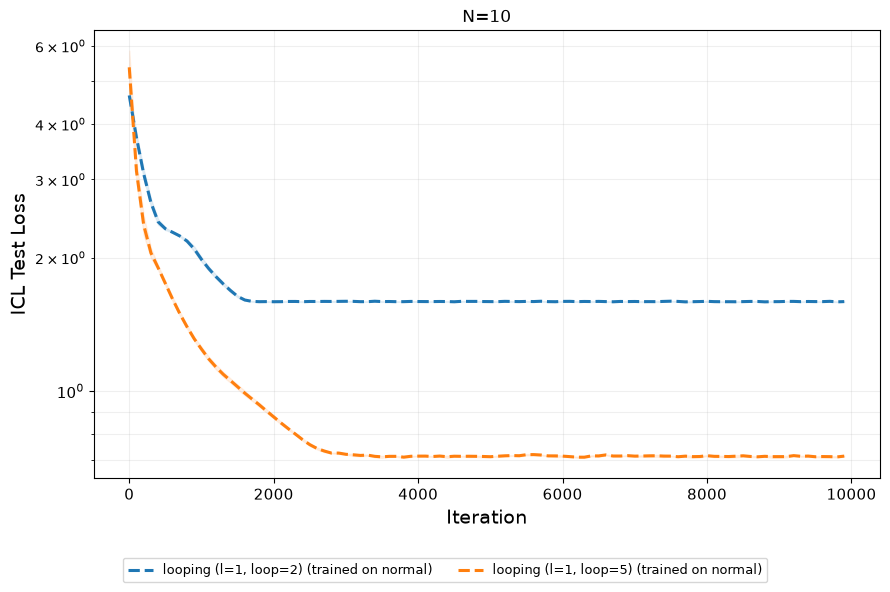

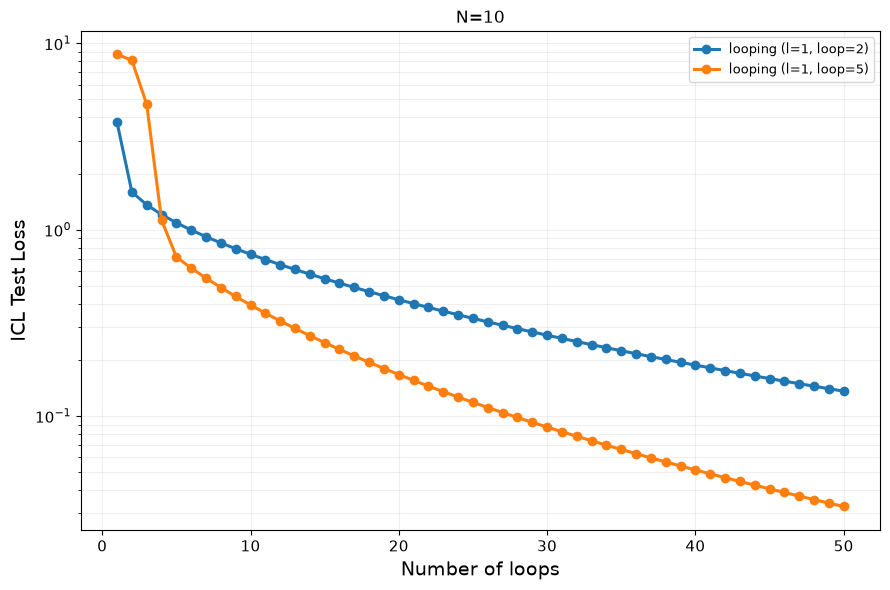

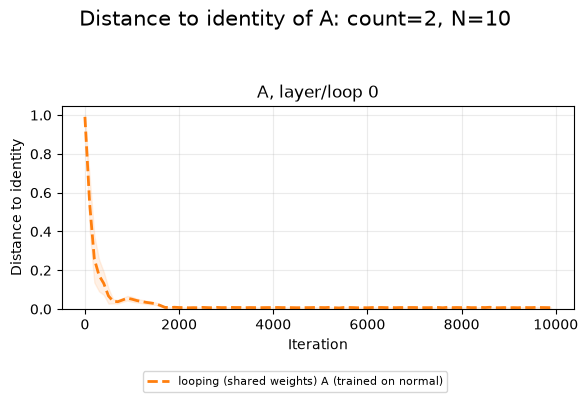

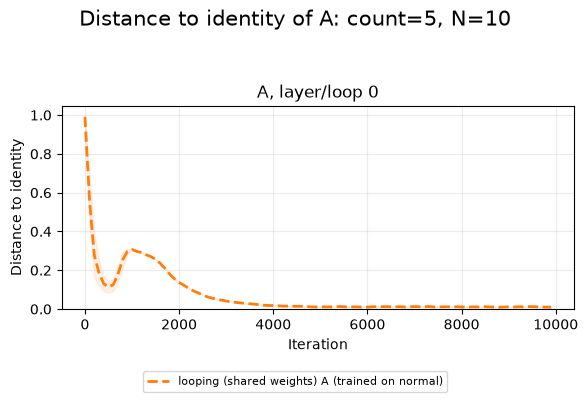

In [25]:
# Plot the adjusted-distribution test loss by training iteration.
plot_loss_curves(
    oos_loss_dict,
    oos_counts,
    oos_model_types,
    oos_iterations,
    fig_dir=oos_fig_dir,
    filename='adjusted_distribution_test_loss.pdf',
)

# Plot looped-model test loss against the number of inference loops (1..50).
plot_loop_loss_curves(
    oos_loop_loss_dict,
    n_layers_loops=oos_counts,
    loop_counts=range(1, 51),
    fig_dir=oos_fig_dir,
    filename='adjusted_distribution_loss_vs_loop_count.pdf',
)

# Plot distance-to-identity for the trained looped-model parameters.
plot_dist_to_identity(
    oos_dist_dict,
    oos_counts,
    oos_iterations,
    fig_dir=oos_fig_dir,
)

(0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(1, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(1, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(2, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(2, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)


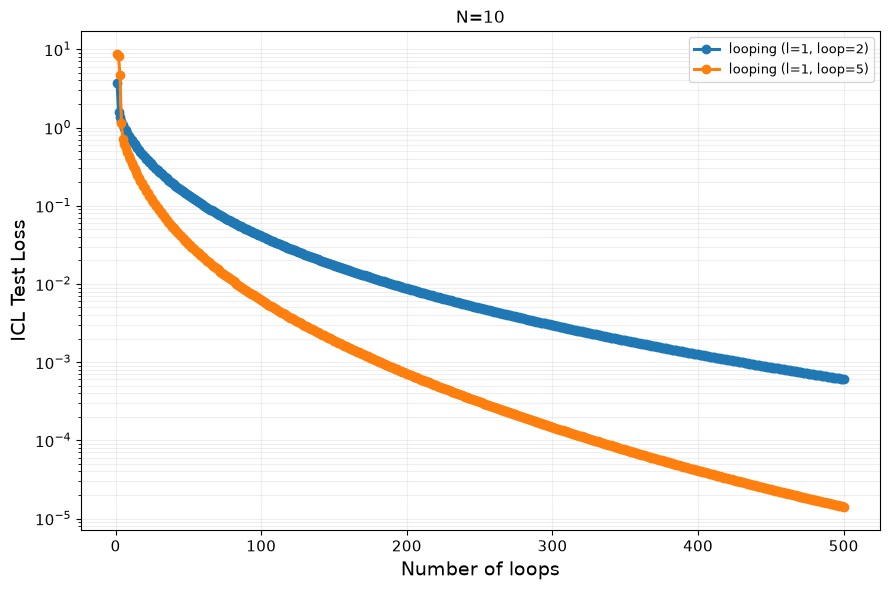

In [26]:
# Sensitivity test: Let's try very large max loop values
oos_loop_loss_dict = compute_looped_loss_by_loop_count(
    oos_looped_hist_dict,
    max_loops=500,
    U=U_test,
    D=D_test,
    test_seed=TEST_SEED,
)

# Plot looped-model test loss against the number of inference loops (1..501).
plot_loop_loss_curves(
    oos_loop_loss_dict,
    n_layers_loops=oos_counts,
    loop_counts=range(1, 501),
    fig_dir=oos_fig_dir,
    filename='adjusted_distribution_loss_vs_extended_loop_count.pdf',
)